# 🥗 NutriScan AI: Train Your Own Nutrition-Table Detector (YOLOv8)

This notebook trains a **YOLOv8 object detection model** on **your own photos** to find the nutrition table on food and drink labels. Then it uses the model to **crop the table before OCR** and measures whether cropping makes the OCR more accurate.

**What you get at the end**
1. A trained model file `best.pt` (your own AI model)
2. Training graphs (loss curves, precision/recall, confusion matrix)
3. Test-set metrics: **mAP@50, mAP@50-95, precision, recall**
4. An OCR experiment: **full photo vs. YOLO-cropped table**, accuracy per nutrient field
5. A results summary you can paste into your report

---
### ✅ Before you start
1. **Runtime → Change runtime type → T4 GPU**, then Save.
2. Have your dataset ready, either:
   - **Option A:** a Roboflow project (labeled with class `nutrition_table`), or
   - **Option B:** a `.zip` exported in **YOLOv8** format (contains `data.yaml`, `train/`, `valid/`, `test/`).
3. Run the cells **from top to bottom** (Shift + Enter).

## 1. Check GPU and install libraries
You should see a **Tesla T4** below. If it says *command not found*, go to Runtime → Change runtime type → GPU.

In [1]:
!pip install pandas


Defaulting to user installation because normal site-packages is not writeable
  Using cached pandas-3.1.1-cp311-cp311-win_amd64.whl.metadata (16 kB)
Using cached pandas-3.1.1-cp311-cp311-win_amd64.whl (11.0 MB)



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA GeForce RTX 2070 SUPER, 8192 MiB


In [9]:
!pip install -q ultralytics roboflow easyocr
import ultralytics
ultralytics.checks()

Ultralytics 8.3.232  Python-3.11.9 torch-2.9.1+cpu CPU (13th Gen Intel Core i5-13400F)
Setup complete  (16 CPUs, 15.8 GB RAM, 887.7/929.9 GB disk)


In [10]:
import os, glob, random, shutil, time, json, re
import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from ultralytics import YOLO

random.seed(42)
WORK = "/content"
print("Ready ✅")

Ready ✅


## 2. Load your dataset
Set `DATA_SOURCE` to `"roboflow"` or `"zip"`, fill in the settings, then run.

**Roboflow:** after clicking *Export → YOLOv8 → Show download code*, copy the values for `api_key`, `workspace`, `project` and `version` from that code into the fields below.

> ⚠️ Don't share the notebook publicly with your API key inside it.

In [11]:
import os
DATA_SOURCE = "roboflow"

RF_API_KEY = os.environ.get("ROBOFLOW_API_KEY", "PASTE_YOUR_ROBOFLOW_KEY")  # never commit the real key
RF_WORKSPACE = "tunlins-workspace"
RF_PROJECT = "nutruscan-label"
RF_VERSION = 1

ZIP_PATH = ""

In [12]:
import os, glob, shutil
from roboflow import Roboflow

WORK = "/content"
DATA_SOURCE = "roboflow"

# ---- Your Roboflow details ----
RF_API_KEY   = os.environ.get("ROBOFLOW_API_KEY", "PASTE_YOUR_ROBOFLOW_KEY")  # never commit the real key
RF_WORKSPACE = "tunlins-workspace"
RF_PROJECT   = "nutriscan-label"
RF_VERSION   = 1

# ---- Download the dataset in YOLOv8 format ----
rf = Roboflow(api_key=RF_API_KEY)
project = rf.workspace(RF_WORKSPACE).project(RF_PROJECT)
dataset = project.version(RF_VERSION).download(
    "yolov8", location=f"{WORK}/dataset", overwrite=True
)
DATASET_DIR = dataset.location

print("Dataset folder:", DATASET_DIR)
print("Train images:", len(glob.glob(f"{DATASET_DIR}/train/images/*")))
print("Valid images:", len(glob.glob(f"{DATASET_DIR}/valid/images/*")))
print("Test images :", len(glob.glob(f"{DATASET_DIR}/test/images/*")))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset in yolov8:: 100%|██████████| 155/155 [00:00<00:00, 3035.85it/s]

Dataset folder: c:\content\dataset
Train images: 66
Valid images: 6
Test images : 3


### Fix `data.yaml` paths
Roboflow exports sometimes use relative paths (`../train/images`) that break training. This cell rewrites them as absolute paths.

In [13]:
import os, yaml

DATA_YAML = f"{DATASET_DIR}/data.yaml"
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)

cfg["path"]  = DATASET_DIR
cfg["train"] = "train/images"
cfg["val"]   = "valid/images"
if os.path.isdir(f"{DATASET_DIR}/test/images"):
    cfg["test"] = "test/images"
else:
    cfg.pop("test", None)

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

HAS_TEST = "test" in cfg
CLASS_NAMES = cfg["names"]
print(open(DATA_YAML).read())

names:
- nutriscan-label
nc: 1
roboflow:
  license: CC BY 4.0
  project: nutriscan-label
  url: https://universe.roboflow.com/tunlins-workspace/nutriscan-label/dataset/1
  version: 1
  workspace: tunlins-workspace
test: test/images
train: train/images
val: valid/images
path: c:\content\dataset



## 3. Look at the dataset
Check that the counts look right and that the green boxes sit on the nutrition tables. **Bad labels make a bad model**, so fix them in Roboflow if they don't.

In [14]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def list_images(split):
    d = f"{DATASET_DIR}/{cfg.get(split, '')}"
    if not os.path.isdir(d):
        return []
    return sorted(p for p in glob.glob(f"{d}/*") if p.lower().endswith(IMG_EXT))

def label_path(img_path):
    base = os.path.splitext(img_path)[0]
    return base.replace(f"{os.sep}images{os.sep}", f"{os.sep}labels{os.sep}") + ".txt"

counts = {s: len(list_images(s)) for s in ["train", "val", "test"]}
n_boxes = 0
for s in counts:
    for p in list_images(s):
        lp = label_path(p)
        if os.path.exists(lp):
            n_boxes += sum(1 for line in open(lp) if line.strip())

print("Images per split:", counts, "| total:", sum(counts.values()))
print("Labeled boxes   :", n_boxes)
print("Classes         :", CLASS_NAMES)
if counts["train"] < 100:
    print("⚠️ Fewer than 100 training images: fine for a test run, but collect more for the final model.")

Images per split: {'train': 66, 'val': 6, 'test': 3} | total: 75
Labeled boxes   : 0
Classes         : ['nutriscan-label']
⚠️ Fewer than 100 training images: fine for a test run, but collect more for the final model.


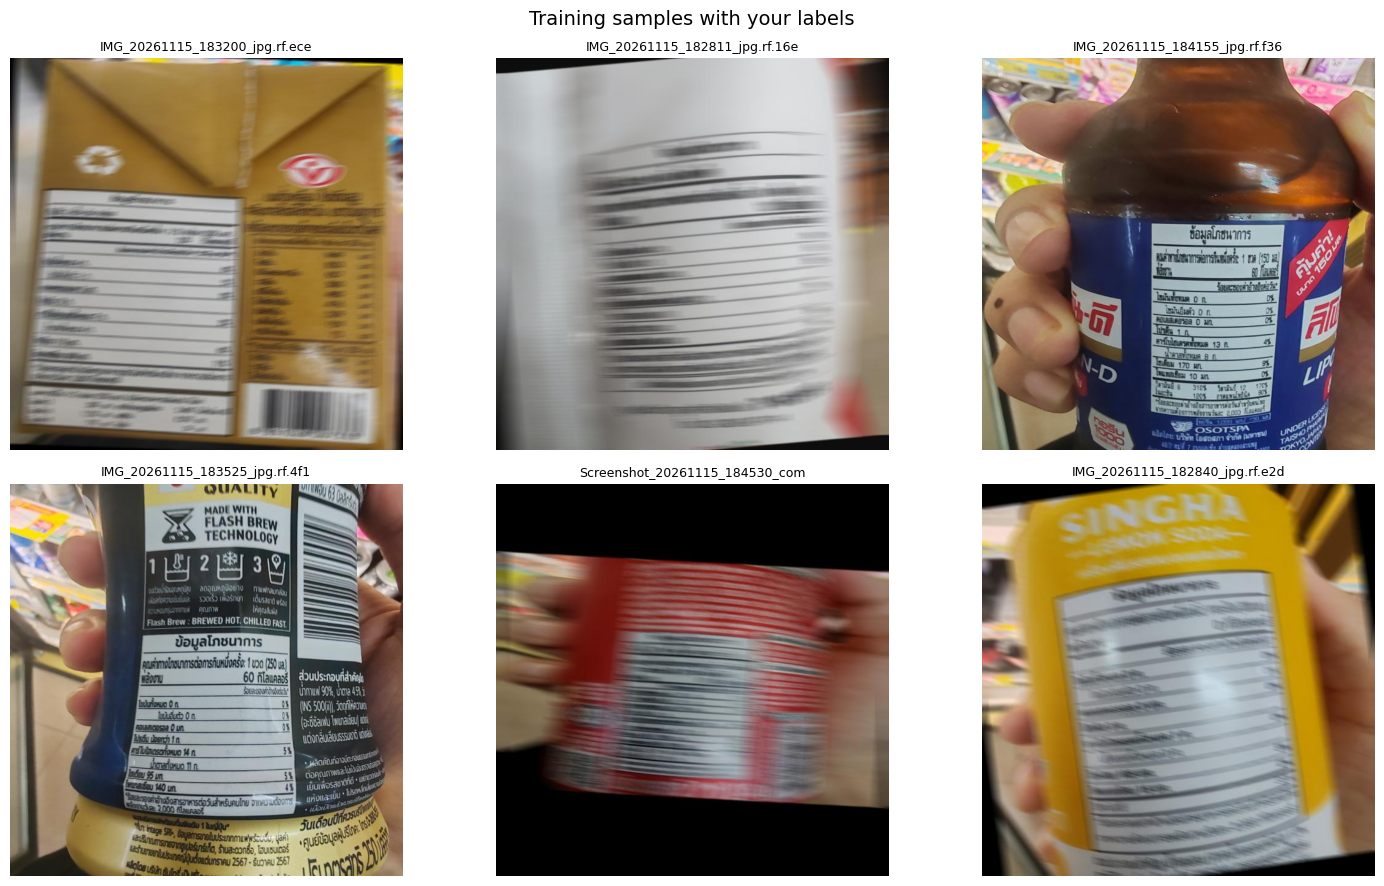

In [15]:
def draw_labels(img_path):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lp = label_path(img_path)
    if os.path.exists(lp):
        for line in open(lp):
            parts = line.split()
            if len(parts) < 5:
                continue
            cx, cy, bw, bh = map(float, parts[1:5])
            x1, y1 = int((cx - bw/2) * w), int((cy - bh/2) * h)
            x2, y2 = int((cx + bw/2) * w), int((cy + bh/2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 0), max(2, w // 200))
    return img

samples = random.sample(list_images("train"), min(6, counts["train"]))
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, samples):
    ax.imshow(draw_labels(p))
    ax.set_title(os.path.basename(p)[:30], fontsize=9)
plt.suptitle("Training samples with your labels", fontsize=14)
plt.tight_layout(); plt.show()

## 4. Train the model
We start from **YOLOv8n pretrained on COCO** and fine-tune it on our photos (**transfer learning**). That's why a few hundred images are enough.

| Setting | Meaning | Suggested |
|---|---|---|
| `MODEL_SIZE` | n = nano (fast), s = small (more accurate) | `"n"` first, try `"s"` later |
| `EPOCHS` | passes over the whole dataset | 30 for a test run, 50–100 final |
| `IMGSZ` | input image size | 640 |
| `BATCH` | images per step | 16 (lower to 8 if out of memory) |

On a T4 GPU this takes about **10–30 minutes** for 200–300 images.

In [16]:
MODEL_SIZE = "n"
EPOCHS     = 50
IMGSZ      = 640
BATCH      = 16
RUN_NAME   = "nutriscan"

model = YOLO(f"yolov8{MODEL_SIZE}.pt")
t0 = time.time()
model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=20,          # stop early if no improvement for 20 epochs
    project=f"{WORK}/runs",
    name=RUN_NAME,
    exist_ok=True,
    seed=42,
    plots=True,
)
TRAIN_MINUTES = (time.time() - t0) / 60
RUN_DIR = f"{WORK}/runs/{RUN_NAME}"
BEST_PT = f"{RUN_DIR}/weights/best.pt"
print(f"✅ Training finished in {TRAIN_MINUTES:.1f} min → {BEST_PT}")

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.232  Python-3.11.9 torch-2.9.1+cpu CPU (13th Gen Intel Core i5-13400F)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\content\dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=nutriscan, nbs=64, nms=False, opset

## 5. Training graphs (for your report)
- **Loss curves** going down = the model is learning.
- **Precision / recall / mAP** going up = it finds tables more accurately.
- If train loss keeps dropping but val loss rises, the model is **overfitting**: collect more varied photos.

📊 results.png


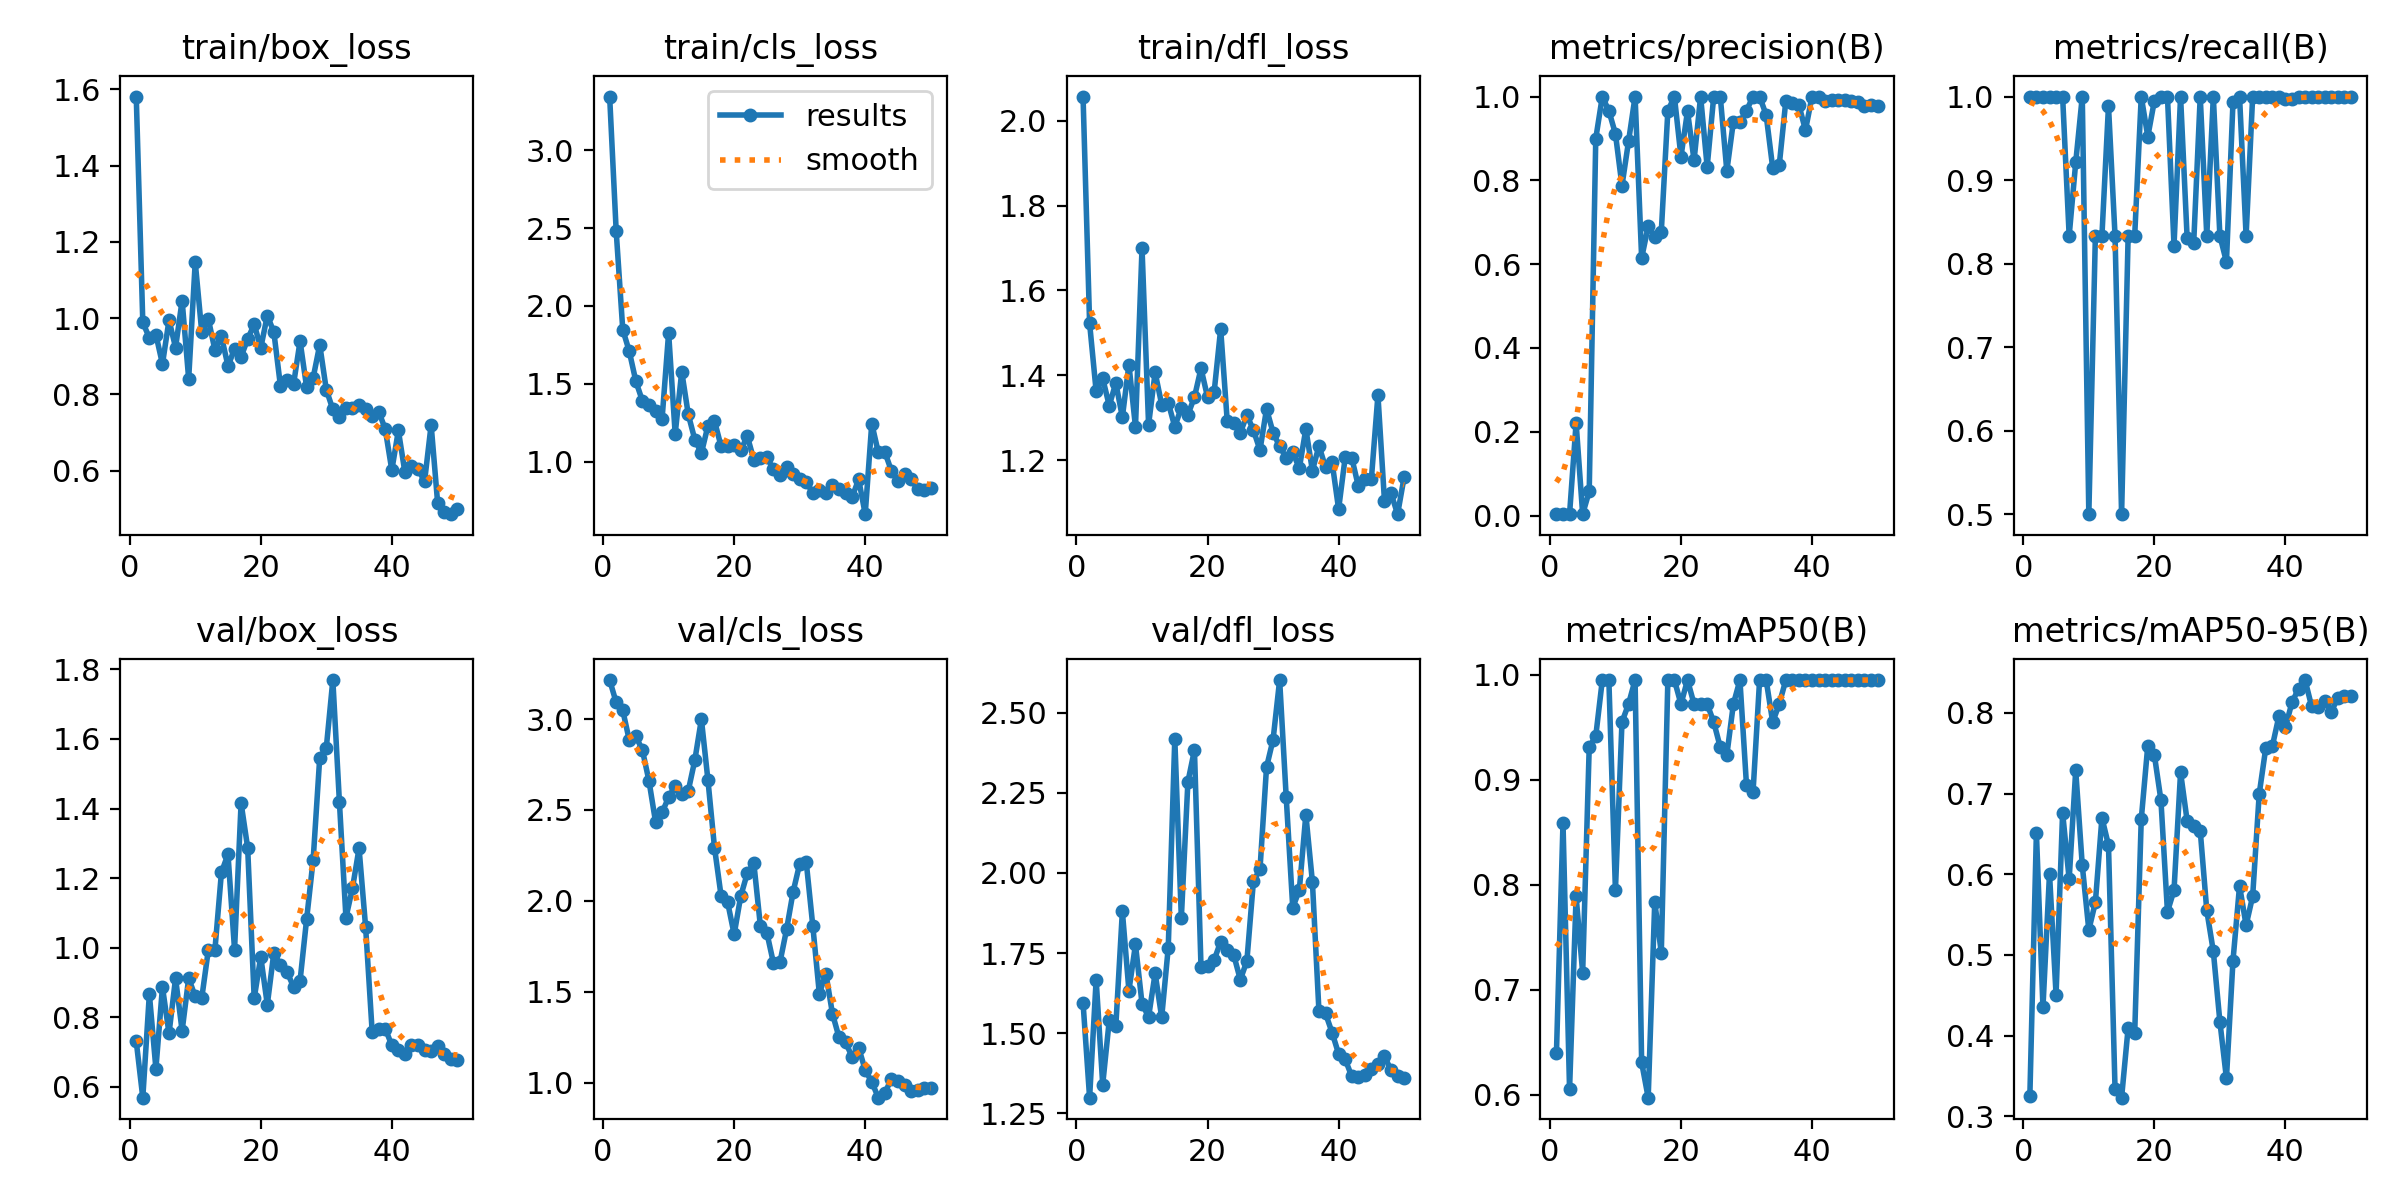

📊 confusion_matrix.png


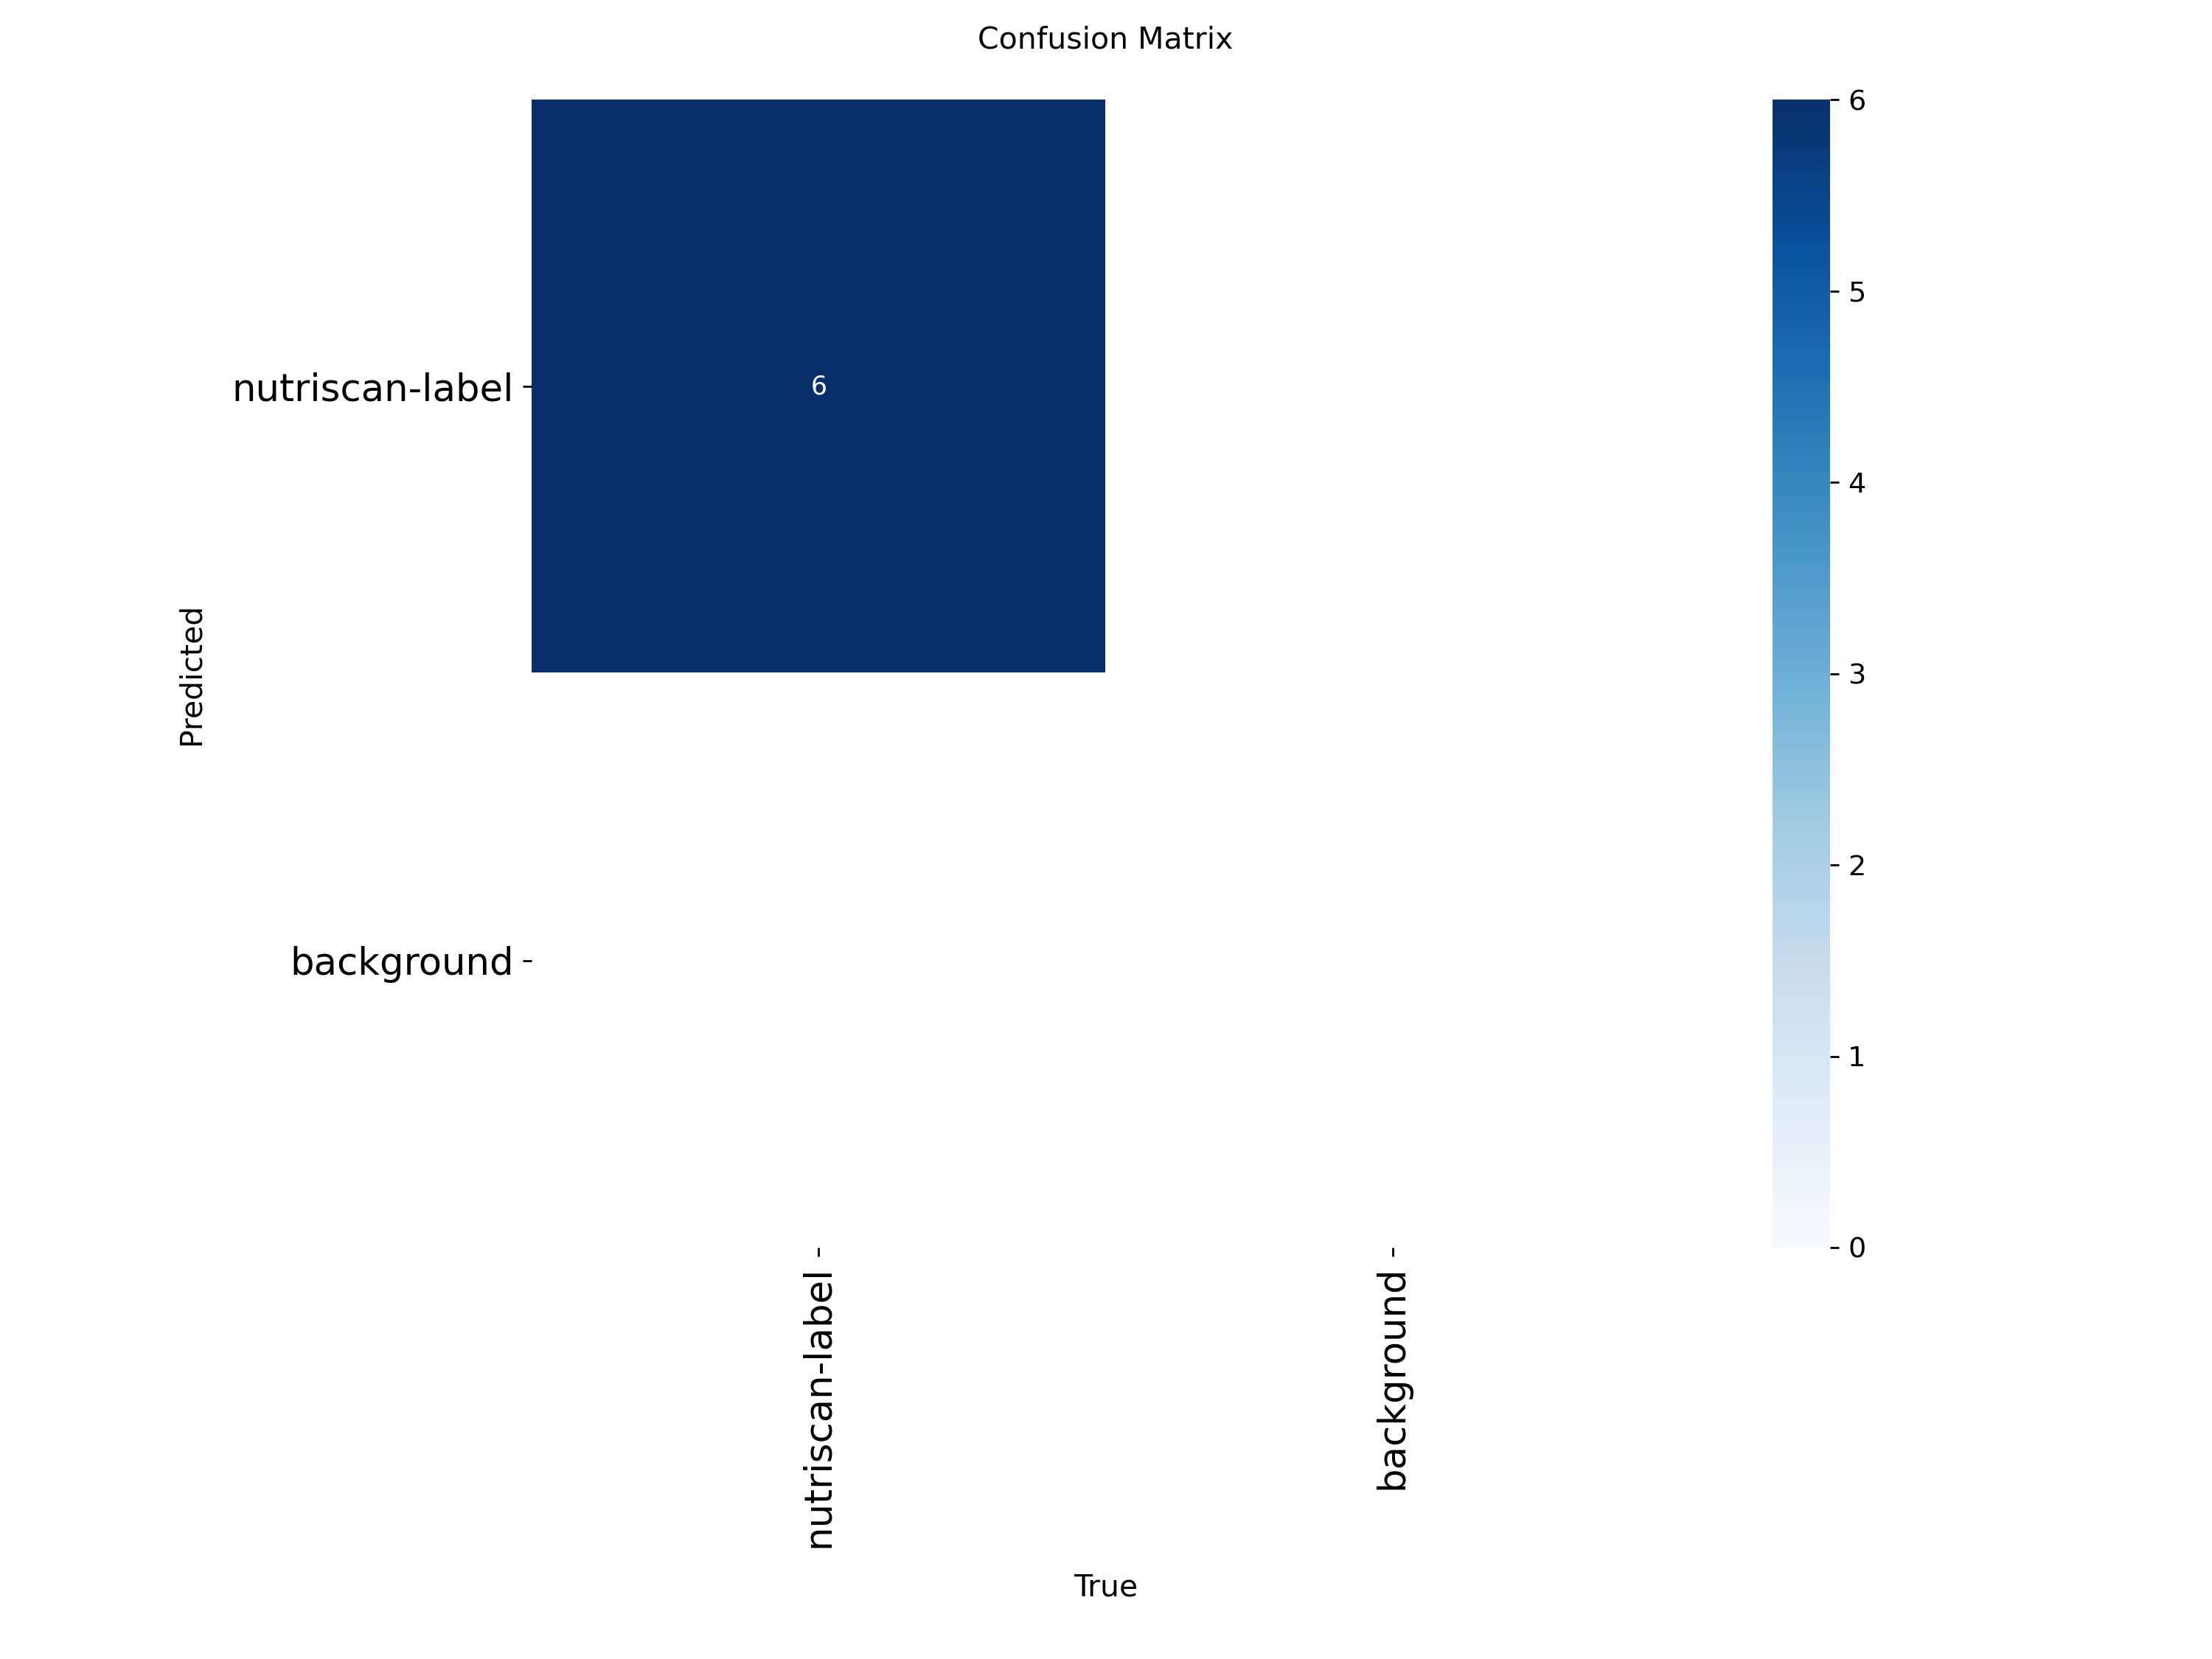

— not found: PR_curve.png
📊 val_batch0_pred.jpg


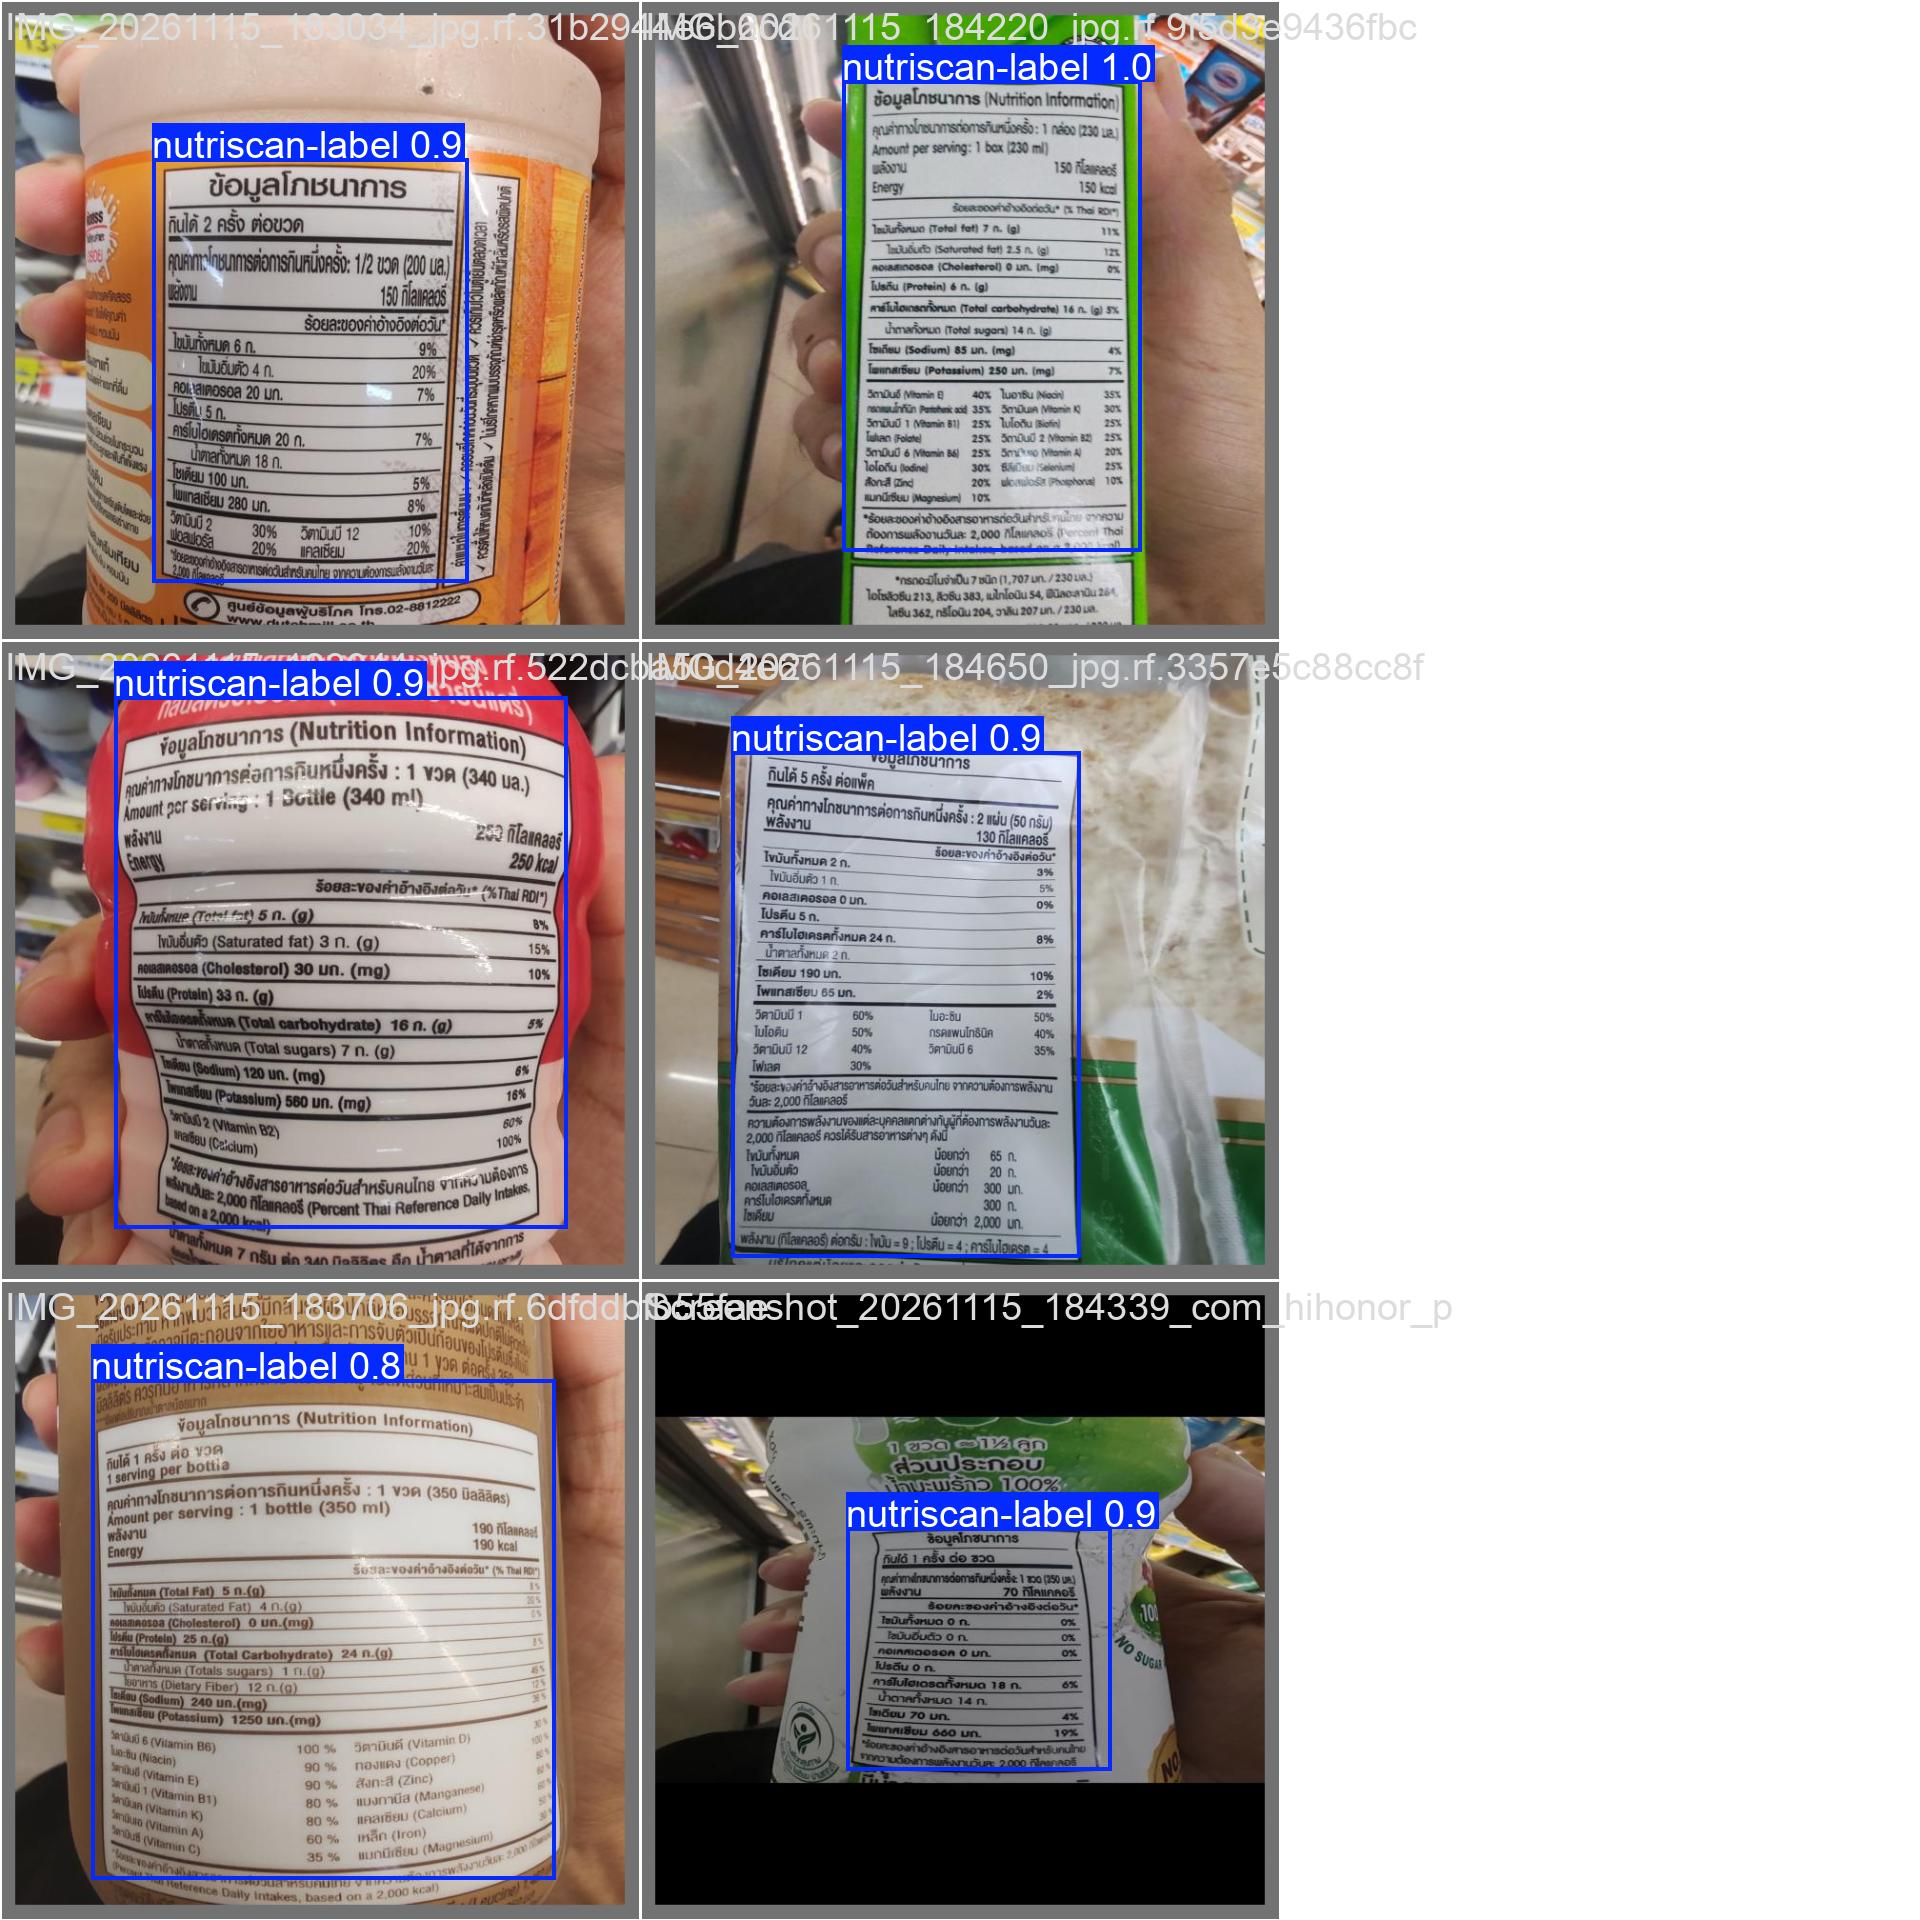

In [17]:
import os
from IPython.display import Image as IPImage, display

RUN_DIR = "/content/runs/nutriscan"

for name in ["results.png", "confusion_matrix.png", "PR_curve.png", "val_batch0_pred.jpg"]:
    p = f"{RUN_DIR}/{name}"
    if os.path.exists(p):
        print("📊", name)
        display(IPImage(filename=p, width=900))
    else:
        print("— not found:", name)

## 6. Evaluate on the test set
The test images were **never seen during training**, so these are your honest results.

- **Precision**: of the boxes the model drew, how many were correct
- **Recall**: of the real tables, how many the model found
- **mAP@50**: overall detection accuracy (box overlaps the truth by ≥ 50%)
- **mAP@50-95**: stricter, averaged over overlap thresholds 50–95%

In [18]:
import pandas as pd
from ultralytics import YOLO

WORK    = "/content"
RUN_DIR = f"{WORK}/runs/nutriscan"
BEST_PT = f"{RUN_DIR}/weights/best.pt"

best = YOLO(BEST_PT)
EVAL_SPLIT = "test" if HAS_TEST else "val"
m = best.val(data=DATA_YAML, split=EVAL_SPLIT, imgsz=640,
             project=f"{WORK}/runs", name="nutriscan_eval", exist_ok=True)

det_metrics = pd.DataFrame([{
    "split": EVAL_SPLIT,
    "images": len(list_images("test" if HAS_TEST else "val")),
    "precision": round(float(m.box.mp), 3),
    "recall": round(float(m.box.mr), 3),
    "mAP@50": round(float(m.box.map50), 3),
    "mAP@50-95": round(float(m.box.map), 3),
}])
det_metrics.to_csv(f"{WORK}/detection_metrics.csv", index=False)
det_metrics

Ultralytics 8.3.232  Python-3.11.9 torch-2.9.1+cpu CPU (13th Gen Intel Core i5-13400F)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 8.70.8 MB/s, size: 64.2 KB)
val: Scanning C:\content\dataset\test\labels... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 272.8it/s 0.0s
val: New cache created: C:\content\dataset\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.4it/s 0.2s
                   all          3          3      0.734      0.936      0.913      0.677
Speed: 0.7ms preprocess, 47.3ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to C:\content\runs\nutriscan_eval


,split,images,precision,recall,mAP@50,mAP@50-95
0,test,3,0.734,0.936,0.913,0.677


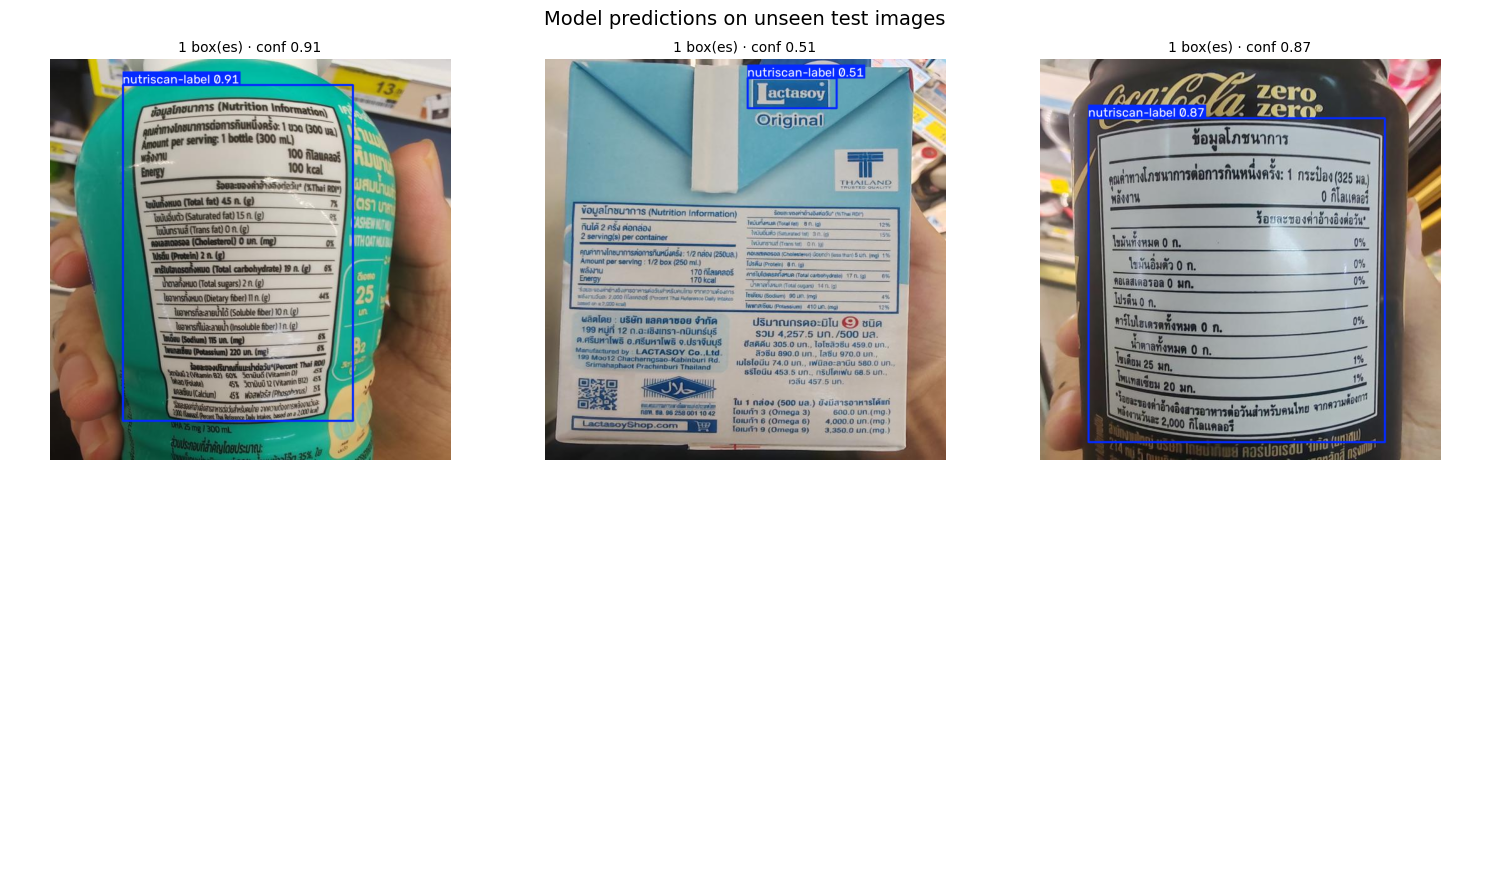

In [19]:
import random, cv2
import matplotlib.pyplot as plt

test_imgs = list_images("test" if HAS_TEST else "val")
show = random.sample(test_imgs, min(6, len(test_imgs)))
results = best.predict(show, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, r in zip(axes.flat, results):
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    n = len(r.boxes)
    ax.set_title(f"{n} box(es)" + (f" · conf {float(r.boxes.conf.max()):.2f}" if n else " · ❌ missed"), fontsize=10)
plt.suptitle("Model predictions on unseen test images", fontsize=14)
plt.tight_layout(); plt.savefig(f"{WORK}/test_predictions.png", dpi=120); plt.show()

## 7. Save your model
Colab deletes files when the session ends, so save `best.pt` to Google Drive and/or download it.

In [20]:
import os, shutil

WORK    = "/content"
RUN_DIR = f"{WORK}/runs/nutriscan"
BEST_PT = f"{RUN_DIR}/weights/best.pt"

try:
    # Running in Google Colab → save to Google Drive
    from google.colab import drive, files
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/NutriScan"
    IN_COLAB = True
except ImportError:
    # Running on your own computer → save to a local folder
    SAVE_DIR = os.path.abspath("NutriScan_results")
    IN_COLAB = False

os.makedirs(SAVE_DIR, exist_ok=True)
shutil.copy(BEST_PT, f"{SAVE_DIR}/best.pt")
shutil.make_archive(f"{SAVE_DIR}/training_run", "zip", RUN_DIR)   # all graphs + weights
for f in ["detection_metrics.csv", "test_predictions.png"]:
    if os.path.exists(f"{WORK}/{f}"):
        shutil.copy(f"{WORK}/{f}", SAVE_DIR)

print("✅ Saved to:", SAVE_DIR)
print("   best.pt is here:", os.path.join(SAVE_DIR, "best.pt"))

if IN_COLAB:
    files.download(BEST_PT)

✅ Saved to: c:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web\NutriScan_results
   best.pt is here: c:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web\NutriScan_results\best.pt


In [21]:
pip install easyocr


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 8. Use the model: detect → crop → OCR → nutrients
This is the pipeline your app will use:
1. **YOLO** finds the nutrition table and crops it
2. **Preprocessing** (upscale + grayscale + CLAHE contrast)
3. **EasyOCR** reads Thai + English text
4. **Parsing** groups the text into lines and extracts nutrient values with regex

In [22]:
import os, re, json, cv2
import matplotlib.pyplot as plt
import easyocr
from ultralytics import YOLO

best = YOLO("/content/runs/nutriscan/weights/best.pt")

try:
    import torch; USE_GPU = torch.cuda.is_available()
except Exception:
    USE_GPU = False
reader = easyocr.Reader(["th", "en"], gpu=USE_GPU)

def detect_and_crop(img_path, conf=0.25, pad=0.03):
    img = cv2.imread(img_path)
    r = best.predict(img_path, conf=conf, verbose=False)[0]
    if len(r.boxes) == 0:
        return img, False, 0.0
    i = int(r.boxes.conf.argmax())
    x1, y1, x2, y2 = r.boxes.xyxy[i].tolist()
    h, w = img.shape[:2]
    px, py = (x2 - x1) * pad, (y2 - y1) * pad
    x1, y1 = max(0, int(x1 - px)), max(0, int(y1 - py))
    x2, y2 = min(w, int(x2 + px)), min(h, int(y2 + py))
    return img[y1:y2, x1:x2], True, float(r.boxes.conf[i])

def preprocess(img):
    if img.shape[1] < 1000:
        s = 1000 / img.shape[1]
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)

def group_lines(ocr_results, y_tol=0.6):
    items = []
    for box, text, _ in ocr_results:
        ys = [p[1] for p in box]; xs = [p[0] for p in box]
        items.append(((min(ys) + max(ys)) / 2, min(xs), max(ys) - min(ys), text))
    items.sort()
    lines = []
    for yc, x, h, t in items:
        if lines and abs(yc - lines[-1]["y"]) < y_tol * max(h, lines[-1]["h"]):
            lines[-1]["parts"].append((x, t))
        else:
            lines.append({"y": yc, "h": h, "parts": [(x, t)]})
    return [" ".join(t for _, t in sorted(l["parts"])) for l in lines]

def run_ocr(img):
    return group_lines(reader.readtext(preprocess(img)))

NUTRIENTS = {
    "energy_kcal":  ["energy", "calories", "พลังงาน"],
    "total_fat_g":  ["total fat", "ไขมันทั้งหมด"],
    "sat_fat_g":    ["saturated", "ไขมันอิ่มตัว"],
    "protein_g":    ["protein", "โปรตีน"],
    "carbs_g":      ["carbohydrate", "คาร์โบไฮเดรต"],
    "sugar_g":      ["sugar", "น้ำตาล"],
    "sodium_mg":    ["sodium", "โซเดียม"],
    "potassium_mg": ["potassium", "โพแทสเซียม"],
}
NUM = re.compile(r"\d{1,3}(?:,\d{3})+|\d+(?:\.\d+)?")

def clean_text(t):
    t = t.lower()
    t = re.sub(r"(?<![a-z])o(?=\s*(?:g\b|mg\b|kcal|ก|มก))", "0", t)
    t = re.sub(r"(?<=\d)\s*,(?=\d(?!\d\d))", ".", t)
    return t

def parse_nutrients(lines):
    out = {k: None for k in NUTRIENTS}
    for line in lines:
        l = clean_text(line)
        for key, kws in NUTRIENTS.items():
            if out[key] is not None:
                continue
            for kw in kws:
                i = l.find(kw)
                if i == -1:
                    continue
                if key == "total_fat_g" and "saturated" in l:
                    continue
                m = NUM.search(l, i + len(kw))
                if m:
                    out[key] = float(m.group().replace(",", ""))
                    break
    return out

print("Pipeline ready ✅ | GPU:", USE_GPU)

Using CPU. Note: This module is much faster with a GPU.


Pipeline ready ✅ | GPU: False


In [23]:
# Keywords in English and Thai for each nutrient (order matters: more specific first)
NUTRIENTS = {
    "energy_kcal":  ["energy", "calories", "พลังงาน"],
    "total_fat_g":  ["total fat", "ไขมันทั้งหมด"],
    "sat_fat_g":    ["saturated", "ไขมันอิ่มตัว"],
    "protein_g":    ["protein", "โปรตีน"],
    "carbs_g":      ["carbohydrate", "คาร์โบไฮเดรต"],
    "sugar_g":      ["sugar", "น้ำตาล"],
    "sodium_mg":    ["sodium", "โซเดียม"],
    "potassium_mg": ["potassium", "โพแทสเซียม"],
}
NUM = re.compile(r"\d{1,3}(?:,\d{3})+|\d+(?:\.\d+)?")

def clean_text(t):
    t = t.lower()
    t = re.sub(r"(?<![a-z])[o](?=\s*(?:g\b|mg\b|kcal|ก|มก))", "0", t)  # 'O g' → '0 g'
    t = re.sub(r"(?<=\d)\s*[,](?=\d(?!\d\d))", ".", t)              # '2,5 g' → '2.5 g'
    return t

def parse_nutrients(lines):
    # Find the first number that comes after a nutrient keyword on the same line.
    out = {k: None for k in NUTRIENTS}
    for line in lines:
        l = clean_text(line)
        for key, kws in NUTRIENTS.items():
            if out[key] is not None:
                continue
            for kw in kws:
                i = l.find(kw)
                if i == -1:
                    continue
                if key == "total_fat_g" and "saturated" in l:
                    continue
                m = NUM.search(l, i + len(kw))
                if m:
                    out[key] = float(m.group().replace(",", ""))
                    break
    return out

# quick self-test with text like the grape-juice label
demo = ["Energy 90 kcal", "ไขมันทั้งหมด (Total fat) O ก. (g) 0%", "Saturated fat 0 g 0%",
        "Total carbohydrate 23 g 8%", "Total sugars 16 g", "Sodium 280 mg 14%",
        "Potassium 75 mg 2%", "พลังงานวันละ 2,000 กิโลแคลอรี"]
print(parse_nutrients(demo))

{'energy_kcal': 90.0, 'total_fat_g': 0.0, 'sat_fat_g': 0.0, 'protein_g': None, 'carbs_g': 23.0, 'sugar_g': 16.0, 'sodium_mg': 280.0, 'potassium_mg': 75.0}


### Try it on one photo
Upload any label photo (for example your grape-juice bottle) and see every step.

Photo: C:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web\eval_photos\20261115_154936.jpg


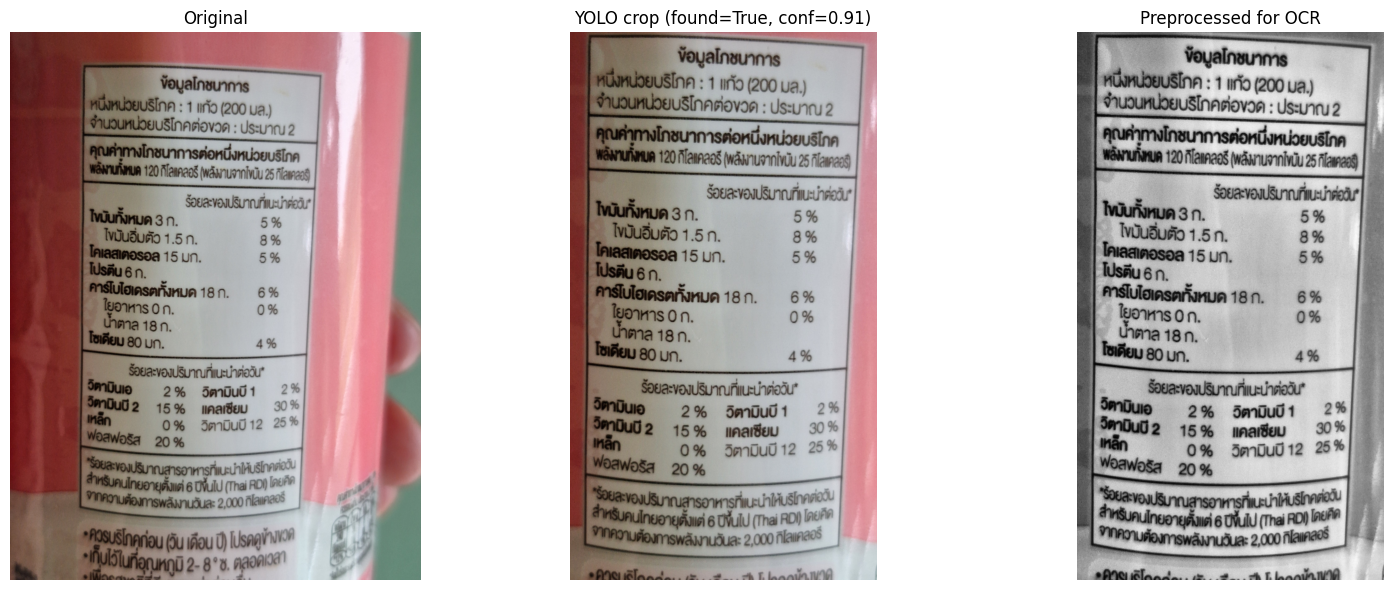

'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.


📝 OCR lines:
   ข้อบูลโกชนาการ
   หนึงหน่ายบริโภค:1 แก้ว(200 มล.)
   จ่านวนหน่วยบริโกค ต่อขวด . ประมาณ2
   คุณค่าทางโกชนาการต่อหนึ่งหน่วยบริโภค
   เล็ททัพทาฆกิสคลร์/แลิฬามททไพนซิกิลทาต์
   ร้อยละของปริบาณที่เนะนำต่ววบ*
   ไพันทิ้งหมด3ก. 5 %
   ไขมันอิ่มตัว 1.5ก. 8 %
   โคเลสเตอรอล 15มก. 5 %
   โปรตีน6ก.
   คาร์โบไอเครคทิ้งหมด 18ก. 6 %
   ใยอาหาร on. 0 %
   นาตาล 18n.
   โซเคียม 80 มก. 4 %
   ร้อยละของปริมาณที่เนะน่าต่อวัน*
    วิตามินเอ 2 %  วิดามินบี1 2 %
    วิตามินบี 2 15 % แคลเซียม 30 %
   เหลิก 0 %  วิตามินบี12 25 %
   ฟอสฟอรัส 20 %
   ๓ารคบทยอายุติเต้ เร้อยละขอฟปริบาณสารอาหารทื่เนะนาไมรึกคต่าน ดดยคิด
   6unul thaird)
   ทาความต้องทารพลิงานวันละ2,0 กิโลเคลอรี
   วาาลaราาร ตอรรรต โกามาแวา

🥗 Extracted nutrients:
{
  "energy_kcal": null,
  "total_fat_g": null,
  "sat_fat_g": 1.5,
  "protein_g": 6.0,
  "carbs_g": null,
  "sugar_g": null,
  "sodium_mg": null,
  "potassium_mg": null
}


In [25]:
PHOTO_PATH = r"C:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web\eval_photos\20261115_154936.jpg"   # e.g. r"C:\Users\Tun\Pictures\grape_label.jpg"

if not PHOTO_PATH:
    PHOTO_PATH = list_images("test")[0]
print("Photo:", PHOTO_PATH)

crop, found, c = detect_and_crop(PHOTO_PATH)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(cv2.cvtColor(cv2.imread(PHOTO_PATH), cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")
axes[1].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); axes[1].set_title(f"YOLO crop (found={found}, conf={c:.2f})")
axes[2].imshow(preprocess(crop), cmap="gray"); axes[2].set_title("Preprocessed for OCR")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

lines = run_ocr(crop)
print("📝 OCR lines:")
print("\n".join("   " + l for l in lines))
print("\n🥗 Extracted nutrients:")
print(json.dumps(parse_nutrients(lines), indent=2, ensure_ascii=False))

In [26]:
from difflib import SequenceMatcher

NUTRIENTS = {
    "energy_kcal":  ["energy", "calories", "พลังงาน"],
    "total_fat_g":  ["total fat", "ไขมันทั้งหมด"],
    "sat_fat_g":    ["saturated", "ไขมันอิ่มตัว"],
    "protein_g":    ["protein", "โปรตีน"],
    "carbs_g":      ["carbohydrate", "คาร์โบไฮเดรตทั้งหมด", "คาร์โบไฮเดรต", "คาร์โบ"],
    "sugar_g":      ["sugar", "น้ำตาล", "น้ำตาลทั้งหมด"],
    "sodium_mg":    ["sodium", "โซเดียม"],
    "potassium_mg": ["potassium", "โพแทสเซียม"],
}
OTHER_WORDS = ["cholesterol", "คอเลสเตอรอล", "โคเลสเตอรอล", "fiber", "ใยอาหาร", "vitamin",
               "วิตามิน", "calcium", "แคลเซียม", "iron", "เหล็ก", "ฟอสฟอรัส", "หน่วยบริโภค",
               "ร้อยละ", "ข้อมูลโภชนาการ", "คุณค่าทางโภชนาการ", "ไขมันทรานส์", "trans fat"]

def _label_part(line):
    m = re.search(r"\d", line)
    return re.sub(r"[\s().,:*%\-]", "", line[:m.start()] if m else line)

def _similarity(word, label):
    if not label: return 0.0
    return max(SequenceMatcher(None, word, label[:len(word) + e]).ratio() for e in (0, 2, 4))

def parse_nutrients(lines, return_method=False):
    out, method, used = {k: None for k in NUTRIENTS}, {}, set()
    # Pass 1: exact keywords
    for idx, line in enumerate(lines):
        l = clean_text(line)
        for key, kws in NUTRIENTS.items():
            if out[key] is not None: continue
            for kw in kws:
                i = l.find(kw)
                if i == -1: continue
                if key == "total_fat_g" and ("saturated" in l or "อิ่มตัว" in l): continue
                m = NUM.search(l, i + len(kw))
                if m:
                    out[key] = float(m.group().replace(",", "")); method[key] = "exact"; used.add(idx); break
    # Pass 2: fuzzy match for slightly misread Thai words
    for idx, line in enumerate(lines):
        if idx in used: continue
        l = clean_text(line); m = NUM.search(l); label = _label_part(l)
        if not m or len(label) < 3: continue
        best_key, best = None, 0.0
        for key, kws in NUTRIENTS.items():
            for kw in kws:
                s = _similarity(kw.replace(" ", ""), label)
                if s > best: best_key, best = key, s
        other = max(_similarity(w.replace(" ", ""), label) for w in OTHER_WORDS)
        if best >= 0.5 and best > other and out[best_key] is None:
            out[best_key] = float(m.group().replace(",", "")); method[best_key] = f"fuzzy {best:.2f}"; used.add(idx)
    # Pass 3: estimate energy if it couldn't be read
    c, p, f = out["carbs_g"], out["protein_g"], out["total_fat_g"]
    if out["energy_kcal"] is None and None not in (c, p, f):
        out["energy_kcal"] = float(round(4*c + 4*p + 9*f)); method["energy_kcal"] = "estimated"
    return (out, method) if return_method else out

print(json.dumps(parse_nutrients(lines, return_method=True), indent=2, ensure_ascii=False))

[
  {
    "energy_kcal": 123.0,
    "total_fat_g": 3.0,
    "sat_fat_g": 1.5,
    "protein_g": 6.0,
    "carbs_g": 18.0,
    "sugar_g": 18.0,
    "sodium_mg": 80.0,
    "potassium_mg": null
  },
  {
    "sat_fat_g": "exact",
    "protein_g": "exact",
    "carbs_g": "exact",
    "total_fat_g": "fuzzy 0.78",
    "sugar_g": "fuzzy 0.73",
    "sodium_mg": "fuzzy 0.86",
    "energy_kcal": "estimated"
  }
]


## 9. Experiment: does YOLO cropping improve OCR?
This is your **own evaluation data**, and it makes a strong results section.

1. Run the next cell. It creates `ground_truth.csv` listing your test images.
2. Download it, open it in Excel / Google Sheets, and **type the real values from each label**. Leave a cell empty if that nutrient isn't on the label.
3. Upload the filled file, then run the experiment cell.

A field counts as **correct** if the extracted value is within ±5% (or ±0.5) of the true value.

In [27]:
import os
print("Notebook is running in:", os.getcwd())

os.makedirs("eval_photos", exist_ok=True)
print("Put your photos here →", os.path.abspath("eval_photos"))

# delete the empty ground-truth file so it can be recreated
if os.path.exists("ground_truth.csv"):
    os.remove("ground_truth.csv")
    print("Deleted the empty ground_truth.csv")

os.startfile(os.path.abspath("eval_photos"))   # opens the folder in File Explorer (Windows)

Notebook is running in: c:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web
Put your photos here → c:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web\eval_photos
Deleted the empty ground_truth.csv


In [28]:
import os, glob
import pandas as pd

EVAL_DIR = "eval_photos"
GT_FILE  = "ground_truth.csv"
GT_COLS  = list(NUTRIENTS.keys())

eval_imgs = sorted(p for p in glob.glob(f"{EVAL_DIR}/*")
                   if p.lower().endswith((".jpg", ".jpeg", ".png")))
print(f"Found {len(eval_imgs)} photos in {os.path.abspath(EVAL_DIR)}")

if not os.path.exists(GT_FILE):
    gt_template = pd.DataFrame({"filename": [os.path.basename(p) for p in eval_imgs]})
    for col in GT_COLS:
        gt_template[col] = ""
    gt_template.to_csv(GT_FILE, index=False, encoding="utf-8-sig")
    print("✅ Created", os.path.abspath(GT_FILE))
else:
    print("ℹ️", GT_FILE, "already exists, not overwritten")

Found 1 photos in c:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web\eval_photos
✅ Created c:\Users\Admin\Downloads\NutriScan_Web_App(1)\NutriScan_Web_App\nutriscan-web\ground_truth.csv


In [30]:
import time

gt = pd.read_csv(GT_FILE)
img_by_name = {os.path.basename(p): p for p in eval_imgs}
gt = gt[gt["filename"].isin(img_by_name)].reset_index(drop=True)
print(f"{len(gt)} labeled photos. Running OCR twice per photo, please wait…")

def is_correct(pred, true):
    if pd.isna(true):
        return None                     # not on the label: skip
    if pred is None:
        return False
    return abs(pred - float(true)) <= max(0.5, 0.05 * float(true))

rows = []
for n, (_, g) in enumerate(gt.iterrows(), 1):
    path = img_by_name[g["filename"]]
    full = cv2.imread(path)
    crop, found, c = detect_and_crop(path)

    t0 = time.time(); pred_full = parse_nutrients(run_ocr(full)); t_full = time.time() - t0
    t0 = time.time(); pred_crop = parse_nutrients(run_ocr(crop)); t_crop = time.time() - t0
    print(f"  [{n}/{len(gt)}] {g['filename']}  table found={found}  ({t_full:.0f}s + {t_crop:.0f}s)")

    for method, pred, secs in [("Full photo", pred_full, t_full), ("YOLO crop", pred_crop, t_crop)]:
        for col in GT_COLS:
            ok = is_correct(pred[col], g[col])
            if ok is not None:
                rows.append({"image": g["filename"], "method": method, "field": col,
                             "true": g[col], "pred": pred[col], "correct": ok, "seconds": secs})

res = pd.DataFrame(rows)
if res.empty:
    raise ValueError(f"Nothing to score: fill in the true label values in {GT_FILE} "
                     "(blank cells are skipped), then run the cells again.")
res.to_csv("ocr_experiment_details.csv", index=False, encoding="utf-8-sig")

overall = res.groupby("method").agg(field_accuracy=("correct", "mean"),
                                    fields=("correct", "size")).round(3)
overall["avg_sec_per_image"] = (res.drop_duplicates(["image", "method"])
                                   .groupby("method")["seconds"].mean().round(1))
per_field = res.pivot_table(index="field", columns="method", values="correct", aggfunc="mean").round(3)

print("\n=== Overall field accuracy ==="); display(overall)
print("\n=== Accuracy per nutrient ==="); display(per_field)

1 labeled photos. Running OCR twice per photo, please wait…


'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.


  [1/1] 20261115_154936.jpg  table found=True  (17s + 14s)

=== Overall field accuracy ===


,field_accuracy,fields,avg_sec_per_image
method,,,
Full photo,1.0,7,16.8
YOLO crop,1.0,7,14.3



=== Accuracy per nutrient ===


method,Full photo,YOLO crop
field,,
carbs_g,1.0,1.0
energy_kcal,1.0,1.0
protein_g,1.0,1.0
sat_fat_g,1.0,1.0
sodium_mg,1.0,1.0
sugar_g,1.0,1.0
total_fat_g,1.0,1.0


In [31]:
print("Photos in folder:", len(eval_imgs))
print([os.path.basename(p) for p in eval_imgs][:5])

gt_check = pd.read_csv(GT_FILE)
print("\nRows in CSV:", len(gt_check))
print("Columns:", list(gt_check.columns))
print("Filenames that match a photo:", gt_check["filename"].isin(img_by_name).sum())
print("Filled values per column:")
print(gt_check[GT_COLS].notna().sum())
display(gt_check.head())

Photos in folder: 1
['20261115_154936.jpg']

Rows in CSV: 1
Columns: ['filename', 'energy_kcal', 'total_fat_g', 'sat_fat_g', 'protein_g', 'carbs_g', 'sugar_g', 'sodium_mg', 'potassium_mg']
Filenames that match a photo: 1
Filled values per column:
energy_kcal     1
total_fat_g     1
sat_fat_g       1
protein_g       1
carbs_g         1
sugar_g         1
sodium_mg       1
potassium_mg    0
dtype: int64


,filename,energy_kcal,total_fat_g,sat_fat_g,protein_g,carbs_g,sugar_g,sodium_mg,potassium_mg
0,20261115_154936.jpg,120,3,1.5,6,18,18,80,NaN


In [32]:
def is_correct(pred, true):
    if pd.isna(true):
        return None                      # nutrient not on label: skip
    if pred is None:
        return False
    return abs(pred - float(true)) <= max(0.5, 0.05 * float(true))

rows = []
for _, g in gt.iterrows():
    path = img_by_name[g["filename"]]
    full = cv2.imread(path)
    crop, found, c = detect_and_crop(path)

    t0 = time.time(); pred_full = parse_nutrients(run_ocr(full)); t_full = time.time() - t0
    t0 = time.time(); pred_crop = parse_nutrients(run_ocr(crop)); t_crop = time.time() - t0

    for method, pred, secs in [("Full photo", pred_full, t_full), ("YOLO crop", pred_crop, t_crop)]:
        for col in GT_COLS:
            ok = is_correct(pred[col], g[col])
            if ok is not None:
                rows.append({"image": g["filename"], "method": method, "field": col,
                             "true": g[col], "pred": pred[col], "correct": ok, "seconds": secs})

res = pd.DataFrame(rows)
if res.empty:
    raise ValueError(f"Nothing to score: fill in the true label values in {GT_FILE} "
                     "(blank cells are skipped), then run the cells again.")
res.to_csv(f"{WORK}/ocr_experiment_details.csv", index=False)

overall = res.groupby("method").agg(field_accuracy=("correct", "mean"),
                                    fields=("correct", "size")).round(3)
overall["avg_sec_per_image"] = res.drop_duplicates(["image", "method"]).groupby("method")["seconds"].mean().round(2)
per_field = res.pivot_table(index="field", columns="method", values="correct", aggfunc="mean").round(3)

print("=== Overall field accuracy ==="); display(overall)
print("\n=== Accuracy per nutrient ==="); display(per_field)

'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.


=== Overall field accuracy ===


,field_accuracy,fields,avg_sec_per_image
method,,,
Full photo,1.0,7,16.78
YOLO crop,1.0,7,14.36



=== Accuracy per nutrient ===


method,Full photo,YOLO crop
field,,
carbs_g,1.0,1.0
energy_kcal,1.0,1.0
protein_g,1.0,1.0
sat_fat_g,1.0,1.0
sodium_mg,1.0,1.0
sugar_g,1.0,1.0
total_fat_g,1.0,1.0


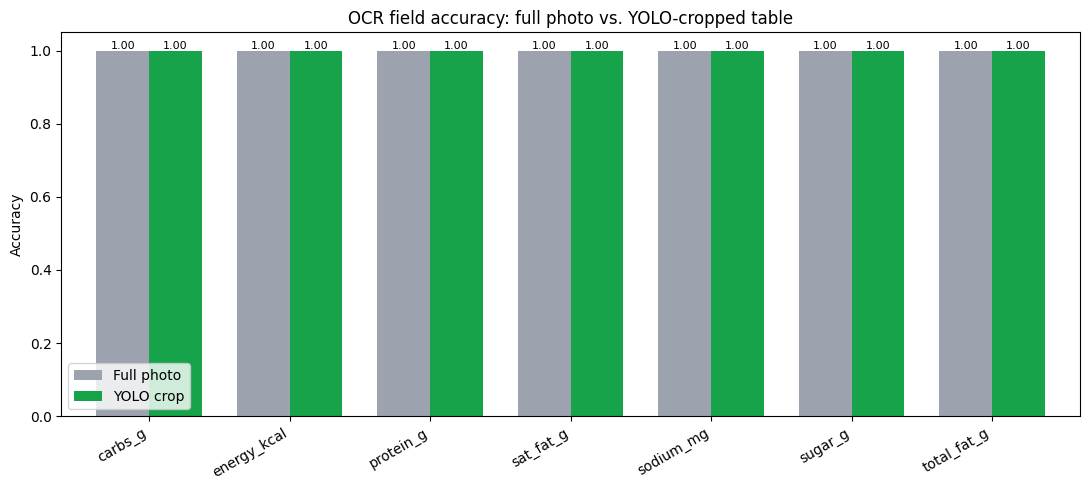

Most common mistakes (YOLO crop):


,image,field,true,pred


In [33]:
ax = per_field.plot(kind="bar", figsize=(11, 5), color=["#9CA3AF", "#16A34A"], width=0.75)
ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1.05); ax.set_xlabel("")
ax.set_title("OCR field accuracy: full photo vs. YOLO-cropped table")
ax.legend(title=""); plt.xticks(rotation=30, ha="right")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(f"{WORK}/ocr_comparison.png", dpi=150); plt.show()

print("Most common mistakes (YOLO crop):")
display(res[(res.method == "YOLO crop") & (~res.correct)].head(15)[["image", "field", "true", "pred"]])

## 10. Results summary for your report

In [34]:
d = det_metrics.iloc[0]
lines = [
    "NUTRISCAN AI: RESULTS SUMMARY",
    "=" * 40,
    f"Dataset: {sum(counts.values())} images "
    f"(train {counts['train']}, val {counts['val']}, test {counts['test']})",
    f"Model: YOLOv8{MODEL_SIZE} (transfer learning from COCO), {EPOCHS} epochs max, "
    f"trained in {TRAIN_MINUTES:.1f} min",
    "",
    f"Nutrition-table detection ({d['split']} set):",
    f"  Precision {d['precision']:.3f} | Recall {d['recall']:.3f} | "
    f"mAP@50 {d['mAP@50']:.3f} | mAP@50-95 {d['mAP@50-95']:.3f}",
]
if "overall" in globals():
    lines += ["", "OCR field accuracy:"]
    for method, r in overall.iterrows():
        lines.append(f"  {method:<11}: {r['field_accuracy']*100:.1f}% "
                     f"({int(r['fields'])} fields, {r['avg_sec_per_image']} s/image)")
summary = "\n".join(lines)
print(summary)
open(f"{WORK}/results_summary.txt", "w").write(summary)

for f in ["results_summary.txt", "ocr_comparison.png", "ocr_experiment_details.csv"]:
    if os.path.exists(f"{WORK}/{f}") and os.path.isdir("/content/drive/MyDrive"):
        shutil.copy(f"{WORK}/{f}", "/content/drive/MyDrive/NutriScan/")
print("\n✅ Everything saved in Google Drive → MyDrive/NutriScan")

NUTRISCAN AI: RESULTS SUMMARY
Dataset: 75 images (train 66, val 6, test 3)
Model: YOLOv8n (transfer learning from COCO), 50 epochs max, trained in 10.3 min

Nutrition-table detection (test set):
  Precision 0.734 | Recall 0.936 | mAP@50 0.913 | mAP@50-95 0.677

OCR field accuracy:
  Full photo : 100.0% (7 fields, 16.78 s/image)
  YOLO crop  : 100.0% (7 fields, 14.36 s/image)

✅ Everything saved in Google Drive → MyDrive/NutriScan


---
## 💡 Tips to improve the model
- **Missed tables?** Add more photos like the ones it missed (curved bottles, glare, dark lighting).
- **Wrong boxes?** Check your labels: every table needs exactly one tight box.
- **Low mAP with < 100 images?** That's normal. Aim for 200–300 varied photos.
- **Try a bigger model:** set `MODEL_SIZE = "s"` and retrain, then compare both in your report.
- **OCR still weak on Thai?** Try PaddleOCR or a vision LLM on the cropped table, and add it as a third method in Section 9.